# 11 - Formation & Interval Analysis

**Part B - Petrophys Curriculum**

A curve-by-curve interpretation answers *"what is the rock doing at this
depth?"*. A **formation analysis** answers the question the asset team actually
asks: *"how much net pay does each formation carry, and what are its average
properties?"*

This notebook takes the curves produced by the dynamic workflow (Notebook 10)
and rolls them up by geological interval. We will:

1. Load **formation tops** from `formations_30_6-5.csv` and per-interval
   **lithology** from `lithology_30_6-5.csv`.
2. Build a **formation / zone hierarchy** with the `Interval` type family.
3. Compute **per-interval summary statistics** with `IntervalAnalyzer`.
4. Produce a **formation-level report** (NTG, net pay, averages per formation)
   with `run_formation_analysis` and `summarize_zones`.
5. Draw a **depth plot with formation shading**.

We use well **30/6-5** and the two CSVs bundled in `petrophys/data/`.

## Learning goals

- Load and query formation tops with `petrophys.formation.FormationTops`.
- Attach per-interval lithology and understand the `Formation` / `Zone` /
  `SubZone` interval hierarchy.
- Compute per-interval net pay / NTG / average properties with
  `IntervalAnalyzer` and `analyze_interval`.
- Run end-to-end formation reporting with
  `petrophys.summation.run_formation_analysis` and roll up zones with
  `summarize_zones`.
- Visualise results as a per-formation table and a shaded depth plot.

### Prerequisites

Notebook 10 (the dynamic workflow) - we reuse the same computed curves here.

## Why this matters

Formation tops turn a continuous log into *accountable units*. NTG and net pay
per formation feed directly into volumetrics and reserves. The library keeps a
clean separation:

- **`petrophys.formation`** - the *geometry*: tops, intervals, and the
  hierarchy (`Formation` > `Zone` > `SubZone`), plus per-interval analysis.
- **`petrophys.summation`** - the *arithmetic*: net-gross, zone summaries, and
  the end-to-end `run_formation_analysis` convenience.

Getting the interval geometry right (correct depth reference, no accidental
overlaps, clipped to the logged interval) is half the job.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.qaqc.standardization import standardize_curves
from petrophys.workflow import run_dynamic_workflow, DynamicWorkflowConfig
from petrophys.data import DATA_DIR

# Formation geometry + per-interval analysis
from petrophys.formation import (
    FormationTops, IntervalAnalyzer, analyze_interval,
    Formation, Zone, IntervalKind,
)
# Summation / reporting
from petrophys.summation import (
    run_formation_analysis, summarize_zones, calculate_zone_summary,
)
from petrophys.visualization.zone_flags import add_zone_shading

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("petrophys", petrophys.__version__)
print("data dir:", DATA_DIR.name)

petrophys 0.1.0
data dir: data


## 1. Load the formation tops

`FormationTops.from_csv` auto-detects the CSV format. Our
`formations_30_6-5.csv` is the *simple* format:
`formation_name, top_depth, bottom_depth, lithology`.

Note that this file mixes **groups** (e.g. `ROGALAND GP.`) with the
**sub-formations** inside them (Balder / Sele / Lista). Those genuinely overlap
in depth, which is a legitimate stratigraphic hierarchy - but it means a naive
`validate()` (which forbids overlaps within the same kind) would raise. We
inspect overlaps instead of enforcing their absence.

In [2]:
FM_CSV   = DATA_DIR / "formations_30_6-5.csv"
LITH_CSV = DATA_DIR / "lithology_30_6-5.csv"

tops = FormationTops.from_csv(str(FM_CSV))
print("Loaded", len(tops), "intervals")
print("Kinds  :", sorted({iv.kind.value for iv in tops}))
print("Overlaps present:", tops.has_overlaps(), "(groups vs sub-formations - expected)")
print()
print(tops.to_dataframe()[["name", "top_depth", "bottom_depth", "thickness", "lithology"]]
      .head(12).to_string(index=False))

Loaded 20 intervals
Kinds  : ['formation']
Overlaps present: True (groups vs sub-formations - expected)

            name  top_depth  bottom_depth  thickness lithology
    NORDLAND GP.      181.0         726.0      545.0     Shale
      Utsira Fm.      726.0         879.0      153.0 Sandstone
   HORDALAND GP.      879.0        1908.0     1029.0     Shale
    ROGALAND GP.     1908.0        2203.0      295.0     Shale
      Balder Fm.     1908.0        2023.0      115.0 Sandstone
        Sele Fm.     2023.0        2123.0      100.0     Shale
       Lista Fm.     2123.0        2203.0       80.0     Shale
    SHETLAND GP.     2203.0        2408.0      205.0     Chalk
CROMER KNOLL GP.     2408.0        2452.0       44.0      Marl
      VIKING GP.     2452.0        2841.0      389.0     Shale
     Draupne Fm.     2452.0        2593.0      141.0     Shale
     Heather Fm.     2593.0        2841.0      248.0     Shale


### Querying the tops

`FormationTops` is a queryable collection: look up by name, find what sits at a
depth, or pull everything in a depth window.

In [3]:
fm = tops.get_by_name("Ness Fm.")
print("get_by_name('Ness Fm.') ->", fm.name, "%.0f-%.0f m, lithology=%s"
      % (fm.top_depth, fm.bottom_depth, fm.lithology))

at = tops.get_at_depth(2900.0)
print("get_at_depth(2900 m)     ->", [iv.name for iv in at], "(group + formation)")

window = tops.get_in_range(3070, 3230)
print("get_in_range(3070-3230)  ->", [iv.name for iv in window])

get_by_name('Ness Fm.') -> Ness Fm. 2841-2865 m, lithology=Sandstone
get_at_depth(2900 m)     -> ['BAAT GP.', 'Etive Fm.'] (group + formation)
get_in_range(3070-3230)  -> ['DUNLIN GP.', 'Drake Fm.', 'Cook Fm.', 'Amundsen Fm.', 'Statfjord Fm.']


## 2. The interval hierarchy: attaching per-interval lithology as zones

The second CSV, `lithology_30_6-5.csv`, is a coarser `top, bottom, lithology`
table - a simplified lithology column with no formation names. We load it as a
separate layer of the hierarchy using `IntervalKind.ZONE`.

The `Interval` type family models the hierarchy explicitly:

| Kind        | Class          | Parent link          |
|-------------|----------------|----------------------|
| `FORMATION` | `Formation`    | `age`                |
| `ZONE`      | `Zone`         | `parent_formation`   |
| `SUB_ZONE`  | `SubZone`      | `parent_zone`        |
| `MANUAL`    | `ManualInterval` | -                  |

The lithology CSV has no name column, so we synthesise a readable name from the
lithology + top depth before loading.

In [4]:
ldf = pd.read_csv(LITH_CSV)
ldf["name"] = ldf["lithology"].str.capitalize() + " @" + ldf["top"].astype(int).astype(str) + "m"
print("Raw lithology intervals:")
print(ldf.to_string(index=False))

lith_zones = FormationTops.from_dataframe(
    ldf, name_col="name", top_col="top", bottom_col="bottom",
    lithology_col="lithology", interval_kind=IntervalKind.ZONE,
)
print("\nLoaded", len(lith_zones), "lithology ZONE intervals; overlaps:", lith_zones.has_overlaps())
print("Kinds:", sorted({iv.kind.value for iv in lith_zones}))

Raw lithology intervals:
   top  bottom lithology             name
 181.0   726.0     shale      Shale @181m
 726.0   879.0 sandstone  Sandstone @726m
 879.0  1908.0     shale      Shale @879m
1908.0  2023.0 sandstone Sandstone @1908m
2023.0  2203.0     shale     Shale @2023m
2203.0  2408.0     chalk     Chalk @2203m
2408.0  2452.0      marl      Marl @2408m
2452.0  2841.0     shale     Shale @2452m
2841.0  2958.0 sandstone Sandstone @2841m
2958.0  3071.0     shale     Shale @2958m
3071.0  3123.0 sandstone Sandstone @3071m
3123.0  3223.0     shale     Shale @3123m
3223.0  3556.0 sandstone Sandstone @3223m

Loaded 13 lithology ZONE intervals; overlaps: False
Kinds: ['zone']


### Linking a lithology zone to its parent formation

With both layers loaded we can walk the hierarchy: for a lithology zone, ask
which formation(s) contain its midpoint. This is how you'd tag a simplified
lithology column back onto the named stratigraphy.

In [5]:
def parent_formations(zone, formation_tops):
    mid = 0.5 * (zone.top_depth + zone.bottom_depth)
    return [iv.name for iv in formation_tops.get_at_depth(mid)
            if iv.kind == IntervalKind.FORMATION]

print("Lithology zone -> containing formation(s):")
for z in list(lith_zones)[3:9]:
    print("  %-18s (%s) -> %s"
          % (z.name, z.lithology, ", ".join(parent_formations(z, tops)) or "(above logged tops)"))

Lithology zone -> containing formation(s):
  Sandstone @1908m   (sandstone) -> ROGALAND GP., Balder Fm.
  Shale @2023m       (shale) -> ROGALAND GP., Sele Fm.
  Chalk @2203m       (chalk) -> SHETLAND GP.
  Marl @2408m        (marl) -> CROMER KNOLL GP.
  Shale @2452m       (shale) -> VIKING GP., Heather Fm.
  Sandstone @2841m   (sandstone) -> BAAT GP., Etive Fm.


## 3. Compute the interpretation curves to summarise

Per-interval statistics need computed curves (`PHIE`, `SW`, `VCL`, `PERM`,
`NET_PAY`, ...). We generate them with the dynamic workflow from Notebook 10,
using the same documented environmental assumptions for 30/6-5.

In [6]:
def load_well():
    w = read_las(petrophys.sample("30_6-5"))
    return standardize_curves(w, rename_curves=True, convert_units=True)

ASSUMED = DynamicWorkflowConfig(
    bht_f=210.0, td_ft=11700.0, rw=0.03, rw_meas_temp_f=210.0,
    salinity_ppm=30000.0, rmf_at_meas_temp=0.05,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,
)

well = load_well()
result = run_dynamic_workflow(well, config=ASSUMED)
print("Workflow success:", result.success)
print("Net-pay curves written:",
      [c for c in ["NET_PAY", "NET_RES", "NET_ROCK", "PHIE", "SW", "VCL", "PERM"]
       if well.has_curve(c)])

Workflow success: True
Net-pay curves written: ['NET_PAY', 'NET_RES', 'NET_ROCK', 'PHIE', 'SW', 'VCL', 'PERM']


## 4. Per-interval summary statistics with `IntervalAnalyzer`

`IntervalAnalyzer` wraps the summation math and adds whole-interval curve
averages, dominant lithology, and data coverage. `analyze_interval` is the
one-shot convenience for a single interval.

In [7]:
# Single interval, the classic Statfjord reservoir sand at the base of the well.
statfjord = Formation("Statfjord (base sand)", 3223.0, 3556.0)
s = analyze_interval(well, statfjord)
zs = s.zone_summary
print("Interval        :", s.interval.name, "(%.0f-%.0f m)"
      % (s.interval.top_depth, s.interval.bottom_depth))
print("Gross thickness :", "%.1f m" % zs.gross_thickness)
print("Net pay         :", "%.1f m" % zs.net_pay)
print("NTG             :", "%.1f %%" % (100 * zs.ntg))
print("Avg PHIE (pay)  :", "%.3f" % zs.avg_phie)
print("Avg Sw   (pay)  :", "%.3f" % zs.avg_sw)
print("Avg PERM (pay)  :", "%.1f mD" % zs.avg_perm)
print("Data coverage   :", "%.0f %%" % s.data_coverage_pct)

Interval        : Statfjord (base sand) (3223-3556 m)
Gross thickness : 333.0 m
Net pay         : 67.8 m
NTG             : 20.4 %
Avg PHIE (pay)  : 0.133
Avg Sw   (pay)  : 0.520
Avg PERM (pay)  : 322.8 mD
Data coverage   : 100 %


### Analysing every formation at once

`analyze_all` runs the summary over an entire `FormationTops` collection,
clipping intervals to the logged depth range first.

In [8]:
analyzer = IntervalAnalyzer(well)
summaries = analyzer.analyze_all(tops.clip_to_well(well))
idf = IntervalAnalyzer.to_dataframe(summaries)

cols = ["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG",
        "Avg PHIE", "Avg Sw", "Avg Perm (mD)", "Dominant Lithology"]
view = idf[cols].copy()
view = view[view["Net Pay"] > 0.1].round(
    {"Top":0,"Bottom":0,"Gross":1,"Net Pay":1,"NTG":3,
     "Avg PHIE":3,"Avg Sw":3,"Avg Perm (mD)":1})
print("Intervals carrying net pay:")
print(view.to_string(index=False))

Intervals carrying net pay:
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw  Avg Perm (mD) Dominant Lithology
HORDALAND GP.  879.0  1908.0 1029.0    239.1 0.232     0.418   0.529         9998.3                   
 ROGALAND GP. 1908.0  2203.0  295.0      0.5 0.002     0.344   0.525        10000.0                   
    Lista Fm. 2123.0  2203.0   80.0      0.5 0.006     0.344   0.525        10000.0                   
 SHETLAND GP. 2203.0  2408.0  205.0      0.3 0.001     0.336   0.508        10000.0                   
   VIKING GP. 2452.0  2841.0  388.9      0.8 0.002     0.254   0.464         5141.2                   
  Heather Fm. 2593.0  2841.0  248.0      0.8 0.003     0.254   0.464         5141.2                   
     BAAT GP. 2841.0  2958.0  117.0     50.6 0.432     0.195   0.333         1609.2                   
     Ness Fm. 2841.0  2865.0   24.1      9.0 0.373     0.182   0.410         1217.3                   
    Etive Fm. 2865.0  2958.0   93.0     41.6 

## 5. Formation-level reporting

### 5a. `summarize_zones` - explicit zone list

When you just have a handful of named depth windows, `summarize_zones` takes a
list of `{name, top, bottom}` dicts and returns `ZoneSummary` objects. Handy
for a quick reservoir-vs-seal roll-up.

In [9]:
zones = [
    {"name": "Brent (Ness+Etive)", "top": 2841, "bottom": 2958},
    {"name": "Cook Fm.",           "top": 3071, "bottom": 3123},
    {"name": "Statfjord",          "top": 3223, "bottom": 3556},
]
zsum = summarize_zones(well, zones)
rows = [{"Zone": z.zone_name, "Gross (m)": round(z.gross_thickness,1),
         "Net Pay (m)": round(z.net_pay,1), "NTG": round(z.ntg,3),
         "Avg PHIE": round(z.avg_phie,3), "Avg Sw": round(z.avg_sw,3),
         "HC index": round(z.hcpv,2)} for z in zsum]
print(pd.DataFrame(rows).to_string(index=False))

              Zone  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  HC index
Brent (Ness+Etive)      117.0         50.6 0.432     0.195   0.333      6.57
          Cook Fm.       52.0          1.1 0.021     0.104   0.568      0.05
         Statfjord      333.0         67.8 0.204     0.133   0.520      4.34


### 5b. `run_formation_analysis` - full end-to-end report

`run_formation_analysis` is the one call that does everything: load the LAS,
standardise, run the dynamic workflow, load the tops CSV, and compute a
`FormationAnalysisResult` with a per-formation summary and totals.

In [10]:
fa = run_formation_analysis(
    str(petrophys.sample("30_6-5")),
    str(FM_CSV),
    bht_f=210.0, td_ft=11700.0, rw=0.03, rw_meas_temp_f=210.0,
    salinity_ppm=30000.0, rmf_at_meas_temp=0.05,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,
)
fdf = fa.to_dataframe()
print("Well          :", fa.well_name)
print("Formations    :", len(fa.summaries))
print("Total gross   : %.1f %s" % (fa.total_gross, fa.depth_unit))
print("Total net pay : %.1f %s" % (fa.total_net_pay, fa.depth_unit))
print()
show = [c for c in fdf.columns if c in
        ("Formation","Top","Bottom") or c.startswith(("Gross","Net Pay")) or c in
        ("NTG","Avg PHIE","Avg Sw","Avg Perm (mD)")]
pay = fdf[fdf["NTG"] > 0.0][show]
print(pay.round(3).to_string(index=False))

Well          : 30/6-5
Formations    : 20
Total gross   : 4441.1 m
Total net pay : 413.0 m

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
HORDALAND GP.  879.0  1908.0   1029.005      239.115 0.232     0.418   0.529       9998.339
 ROGALAND GP. 1908.0  2203.0    295.046        0.457 0.002     0.344   0.525      10000.000
    Lista Fm. 2123.0  2203.0     80.010        0.457 0.006     0.344   0.525      10000.000
 SHETLAND GP. 2203.0  2408.0    204.978        0.305 0.001     0.336   0.508      10000.000
   VIKING GP. 2452.0  2841.0    388.925        0.762 0.002     0.254   0.464       5141.208
  Heather Fm. 2593.0  2841.0    247.955        0.762 0.003     0.254   0.464       5141.208
     BAAT GP. 2841.0  2958.0    117.043       50.597 0.432     0.195   0.333       1609.208
     Ness Fm. 2841.0  2865.0     24.079        8.992 0.373     0.182   0.410       1217.260
    Etive Fm. 2865.0  2958.0     92.964       41.605 0.448     0.197   0.316    

The pay is concentrated in the Brent Group sands (Ness / Etive), the Cook
sandstone, and the Statfjord sands at the base - exactly the clastic reservoirs
you expect in this part of the North Sea. The thick shale groups (Hordaland,
Viking, Dunlin) score near-zero NTG and act as seals/source.

## 6. Depth plot with formation shading

Finally, the visual: an effective-porosity depth track with the **named
formations shaded** behind it. `add_zone_shading` takes a list of
`{top, bottom, name, color}` dicts and paints spans onto an existing axis via
`axhspan`, so it composes with any log track you draw.

We shade only the main reservoir formations to keep the figure readable.

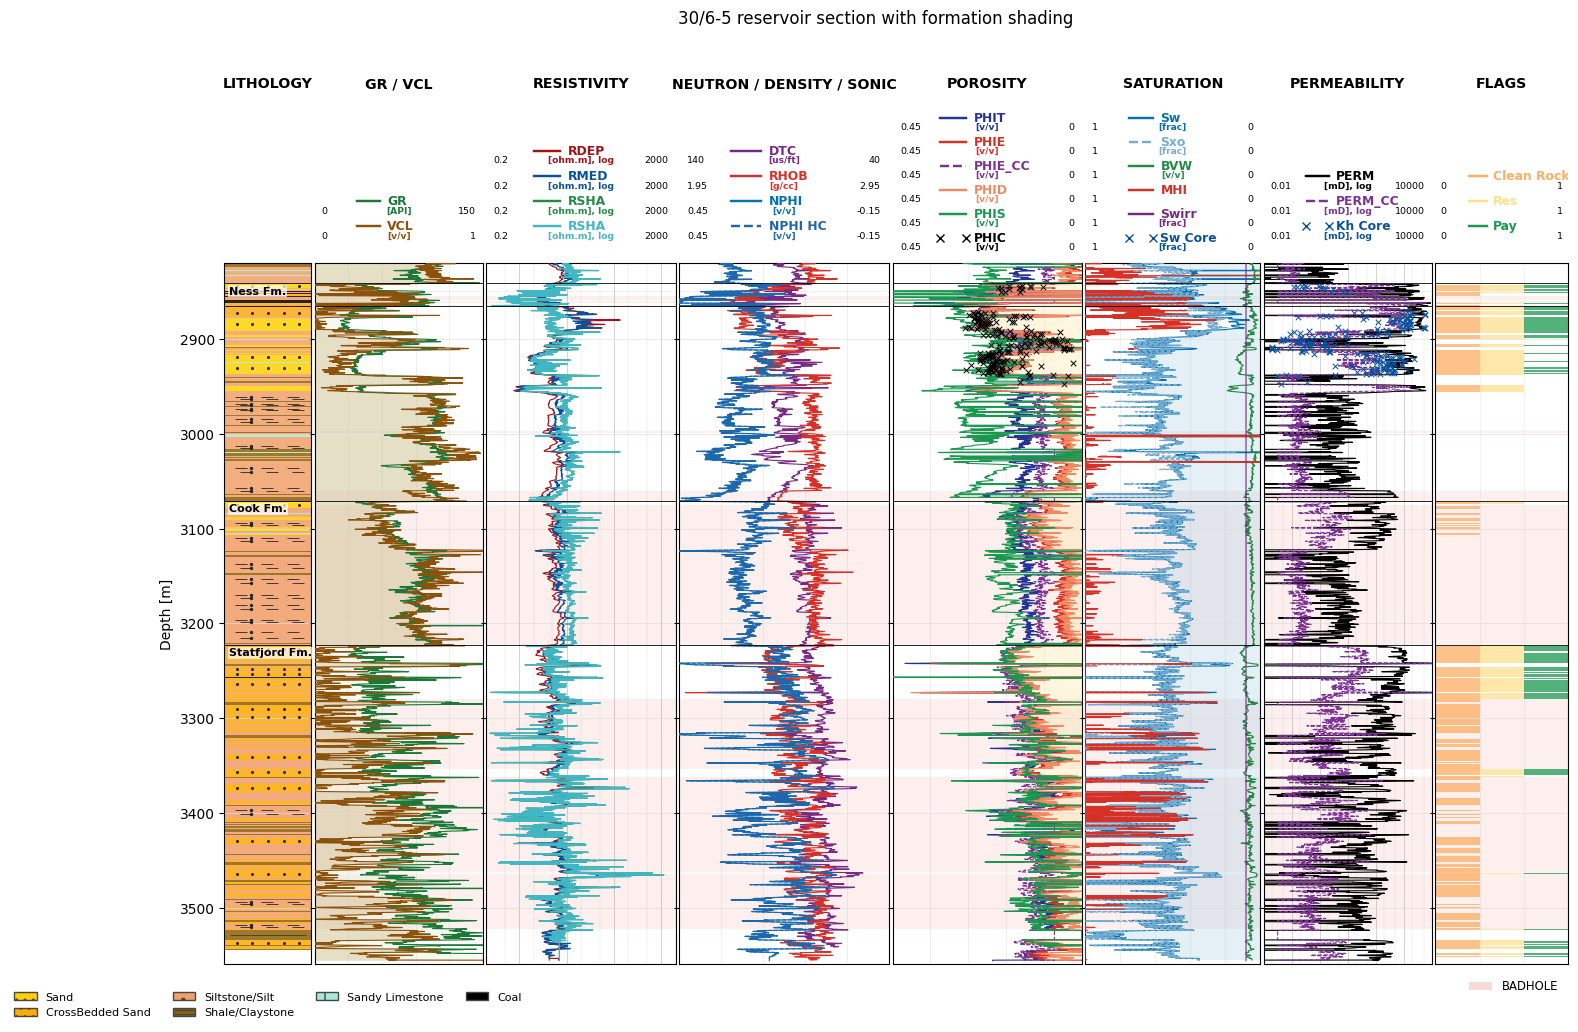

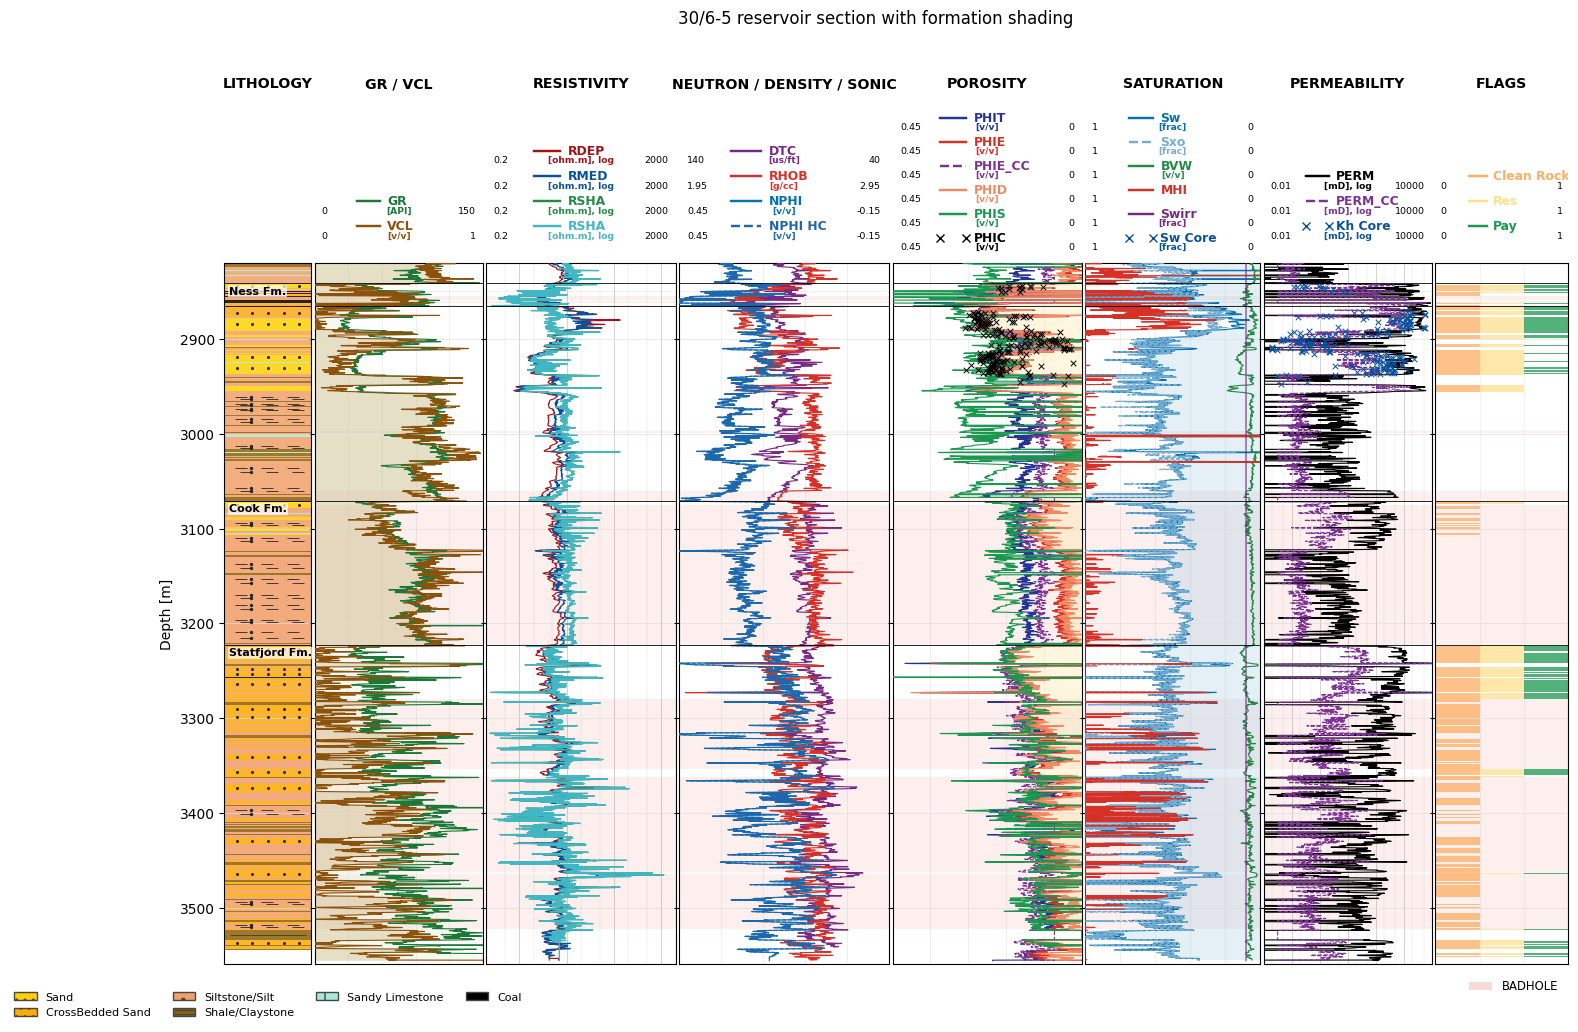

In [11]:
from petrophys.visualization import create_log_viewer

reservoir_fms = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
palette = {"Ness Fm.":"gold", "Etive Fm.":"khaki",
           "Cook Fm.":"orange", "Statfjord Fm.":"sandybrown"}
shade = []
for name in reservoir_fms:
    iv = tops.get_by_name(name)
    if iv is not None:
        shade.append({"top": iv.top_depth, "bottom": iv.bottom_depth,
                      "name": iv.name, "color": palette[name]})

top_d, bot_d = 2820.0, 3560.0

# Library-driven: the "petrophysics" template renders GR, PHIE (POROSITY track)
# and the NET_PAY flag track. Passing the reservoir formations via formation_tops=
# lets the LogViewer draw the named formation markers over every track, so no
# hand-rolled matplotlib / add_zone_shading is needed here.
viewer = create_log_viewer(
    well,
    template_defaults="petrophysics",
    depth_range=(top_d, bot_d),
    formation_tops=shade,
    figsize=(14, 10),
)
viewer.fig.suptitle("30/6-5 reservoir section with formation shading", y=1.0)
viewer.fig


Reading the panel: the shaded reservoir formations line up with the clean-GR,
high-PHIE intervals, and the net-pay flag fires inside them. The shading makes
the "which formation owns this pay?" question immediate.

## Pitfalls & parameter choices

- **Check the depth reference/unit.** `analyze_formations` warns if *no*
  formation overlaps the log - almost always a metres-vs-feet or datum mismatch.
- **Overlapping intervals are legitimate** for group/formation hierarchies;
  don't call `validate()` (which forbids same-kind overlaps) on such a file -
  use `has_overlaps()` / `find_overlaps()` to inspect instead.
- **Clip to the well.** `clip_to_well` (used by `analyze_all`) drops intervals
  outside the logged range and trims partial ones, so gross thicknesses are
  honest.
- **Averages are pay-weighted.** `ZoneSummary.avg_phie/avg_sw` are averaged over
  *net pay* samples; whole-interval averages (`avg_gr`, `avg_rhob`, ...) live on
  the `IntervalSummary`. Permeability is a *geometric* average.
- **`hcpv` on `ZoneSummary` is an index, not a volume** (PHIE*(1-Sw)*net_pay, a
  length). For true OOIP/OGIP use `summation.hydrocarbon_pore_volume`.

## Recap

- `FormationTops.from_csv` / `from_dataframe` load and query the interval
  geometry; the `Formation`/`Zone`/`SubZone` classes model the hierarchy.
- `IntervalAnalyzer` (and `analyze_interval`) give per-interval net pay, NTG,
  averages, dominant lithology, and coverage.
- `summarize_zones` rolls up an explicit zone list; `run_formation_analysis`
  is the end-to-end LAS -> workflow -> per-formation report.
- `add_zone_shading` paints named formations behind any depth track.

## Try it yourself

> **Exercise 1.** Load the lithology CSV as `IntervalKind.ZONE` and run
> `IntervalAnalyzer.analyze_all` on it. Compare net pay bucketed by *lithology*
> against the formation buckets.
>
> **Exercise 2.** Add `Draupne Fm.` (a source-rock shale) to the shaded plot and
> confirm its NTG is ~0.
>
> **Exercise 3.** Re-run `run_formation_analysis` with `sw_cutoff=0.5` and
> compare total net pay against the base run - which formations lose the most?

## What's next

You have now traced a well from raw logs (Notebook 10) all the way to a
formation-level reserves-ready summary. From here, explore batch processing
(`process_las_directory`) to run this same pipeline across a whole field.